# Job Categorizer

This is a new notebook with the revised cleaning, charts, and model comparison. It is separate from the original Colab file, which cannot be overwritten unless a Google account is signed in.

Run the setup cell once. It fetches the analysis code and the public quarterly job-posting files (about 130 MB). The cells below already contain the results of that run, so the figures and scores are visible before anything is executed.

The question is unchanged and narrower than the draft. After the role name is removed from the advertisement, can the remaining text still tell the role families apart? Macro F1 is the score that matters, because about three quarters of the postings are analyst roles.


In [1]:
from pathlib import Path
import urllib.request

def fetch(url, dest):
    dest = Path(dest)
    dest.parent.mkdir(parents=True, exist_ok=True)
    if dest.exists() and dest.stat().st_size > 0:
        print(f"already present: {dest}")
        return
    print(f"downloading {dest.name} ...")
    urllib.request.urlretrieve(url, dest)
    print(f"saved {dest} ({dest.stat().st_size:,} bytes)")

fetch(
    "https://raw.githubusercontent.com/kakaijacob/Special-Operations-Schema/"
    "cursor/jobs-classification-4b7a/Jobs%20Classification/jobs_analysis.py",
    "jobs_analysis.py",
)

base = (
    "https://raw.githubusercontent.com/iweld/data-analyst-job-postings/"
    "main/source_data/csv/"
)
for name in [
    "gsearch_jobs_2022.csv",
    "gsearch_jobs_2023_q1.csv",
    "gsearch_jobs_2023_q2.csv",
    "gsearch_jobs_2023_q3.csv",
]:
    fetch(base + name, Path("data") / name)


downloading jobs_analysis.py ...
saved jobs_analysis.py (33,945 bytes)
downloading gsearch_jobs_2022.csv ...
saved data/gsearch_jobs_2022.csv (26,670,578 bytes)
downloading gsearch_jobs_2023_q1.csv ...
saved data/gsearch_jobs_2023_q1.csv (45,036,270 bytes)
downloading gsearch_jobs_2023_q2.csv ...
saved data/gsearch_jobs_2023_q2.csv (32,968,647 bytes)
downloading gsearch_jobs_2023_q3.csv ...
saved data/gsearch_jobs_2023_q3.csv (32,167,003 bytes)


# Jobs Classification

Revised analysis for the capstone *Job Categorizer for Automated Job Classification and Requirements Analysis*.

The draft notebook labelled a title as a data-analyst job if it merely contained the word "analyst", and as an engineering job if it contained "engineer". The letters "ai" inside an unrelated word were enough to mark a title as machine learning. Those labels were then pasted into the text the models trained on. Several models reported accuracy above 0.90, and the decision tree was ranked first. That test mostly checks whether a model can read a label that was left in its own input.

This notebook asks a narrower question, and a fairer one. After the role name has been removed from the advertisement, can the remaining text — the duties and the tools — still tell the role families apart? The same five model families are kept. The comparison that matters is against a majority-class guess, and the score that matters is macro F1, because three quarters of the postings are analyst roles.

The extract used here is the public quarterly release of Luke Barousse's Google job-search file, covering 4 November 2022 to 8 September 2023. The draft loaded a later snapshot of the same Kaggle file (40,733 rows). This copy has 28,375 rows, every one of them returned for the query "data analyst". The setup cell downloads those quarterly files into `data`.


## 1. Load and clean

Strings are stripped, the "via" prefix is taken off the board name, and locations that differ only by a leading space are treated as the same place. Descriptions shorter than 30 words are dropped. A posting that repeats the same title, employer, place, and opening text is kept once, at its earliest date. Pay is kept for the charts only when the annualised figure falls between $30,000 and $220,000. Wider hourly ranges, such as "10 to 300 an hour", annualise to numbers that are not a salary.


In [2]:
from pathlib import Path
import os
import pandas as pd

from jobs_analysis import (
    clean,
    load_raw,
    make_figures,
    mask_role_language,
    plot_model_results,
    train_models,
)

DATA_DIR = Path(os.environ.get("JOBS_DATA_DIR", "data"))
OUT_DIR = Path(".")

raw = load_raw(DATA_DIR)
print(f"Raw shape: {raw.shape[0]:,} rows, {raw.shape[1]} columns")
df, notes = clean(raw)
print(
    f"Kept {notes['n_clean']:,} postings. "
    f"Dropped {notes['dropped_short_or_blank']:,} with a blank or very short description, "
    f"and {notes['duplicates_removed']:,} repeats."
)
print(f"Window: {notes['date_min']} to {notes['date_max']}")
print("Search terms:", notes["search_terms"])
print(f"Share with any posted pay: {notes['salary_listed_share']:.1%}")
print()
print(df["job_category"].value_counts().to_string())


Raw shape: 28,375 rows, 27 columns
Kept 20,246 postings. Dropped 978 with a blank or very short description, and 7,151 repeats.
Window: 2022-11-04 to 2023-09-08
Search terms: {'data analyst': 20246}
Share with any posted pay: 18.2%

job_category
Data Analyst                   15104
Others                          3554
Data Scientist                   852
Data Engineer                    399
Data Governance and Quality      327
Machine Learning and AI           10


## 2. Role families

A title is labelled by the phrase that appears first, not by the first keyword list that happens to match. "Data analytics" and "data analysis" count as analyst work. "Data engineer", "analytics engineer", "data architect", and "etl" count as engineering. A machine-learning phrase does not override a named occupation in the same title: in this extract those phrases are usually a tool, not the job. Ten titles are machine-learning roles and nothing else. That is too few to model, so they are folded into Others before training and left visible in the counts above.

The rules are explicit, which is their virtue and their limit. "Lead Data Analytic Analyst" stays in Others because the list does not contain every spelling. Others is a mixture, not a profession.


In [3]:
for category in [
    "Data Analyst",
    "Data Scientist",
    "Data Engineer",
    "Data Governance and Quality",
    "Machine Learning and AI",
    "Others",
]:
    print(category)
    sample = df.loc[df["job_category"] == category, "title"].drop_duplicates().head(5)
    print(sample.to_string(index=False))
    print()


Data Analyst
Data Analyst III - Full Time - Days
          Sr. Business Data Analyst
                   Sr. Data Analyst
                       Data Analyst
    Data Analyst - Finance (Remote)

Data Scientist
                         Lead Data Science Analyst
          Staff Data Scientist - Inference, Search
               Data scientist to help find pattern
           Data Scientist II - Marketing Analytics
Data Science Virtual Internship ( 30 Nov - Feb ...

Data Engineer
                             Data Engineer/Analyst
     Data Engineer/Analyst- Healthcare Data Mapper
Sr. Healthcare & Accounting Data Modeler and An...
                                   Data QA And ETL
                        Data Engineering Tech Lead

Data Governance and Quality
Data Quality Analyst II (Remote)
            Data Quality Analyst
  Data Governance Senior Analyst
         Sr Data Quality Analyst
      Data Governance Specialist

Machine Learning and AI
     Machine Learning Operations - Analyst REMO

## 3. What the extract actually looks like

The charts below replace the draft's repeated bar, pie, count, and log-scale pie of the same six counts. A log-scale pie changes the shares. It is not used here.

Two facts should be read before any model score. First, the query was "data analyst", so the analyst bar is the sample design, not a finding about the labour market. Second, the on-site jobs are not a national spread. Almost every posting that names a state names Missouri, Oklahoma, Kansas, or Arkansas. Remote postings, most of them listed as "Anywhere", are a separate and large group. September 2023 is an eight-day stub, not a collapse in hiring.


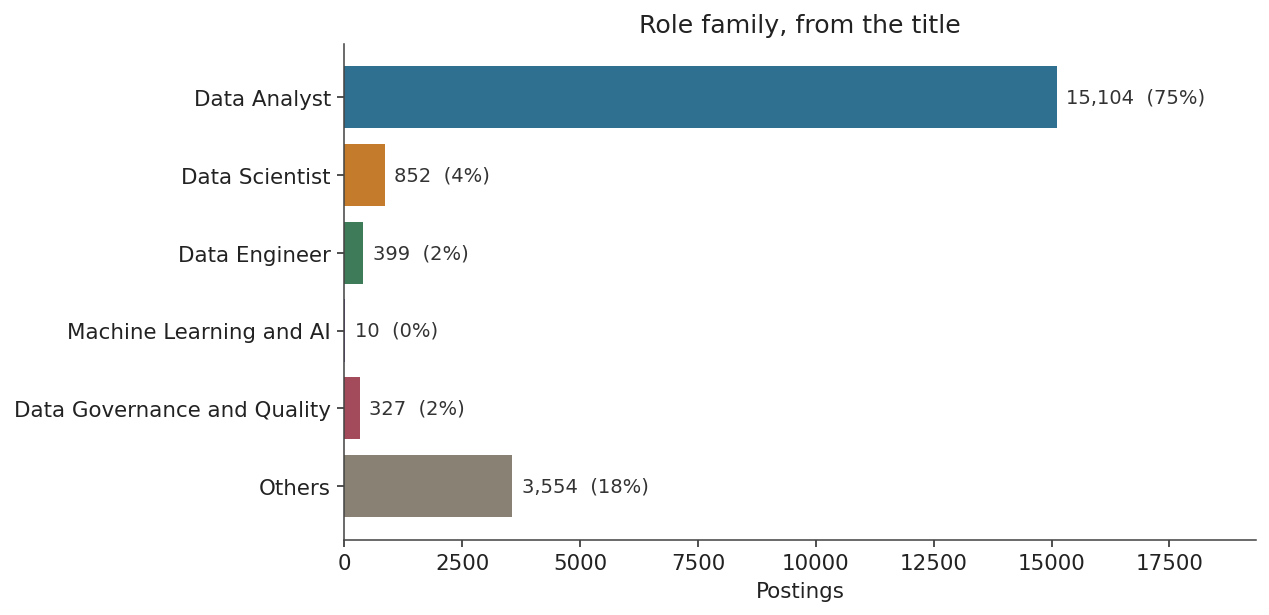

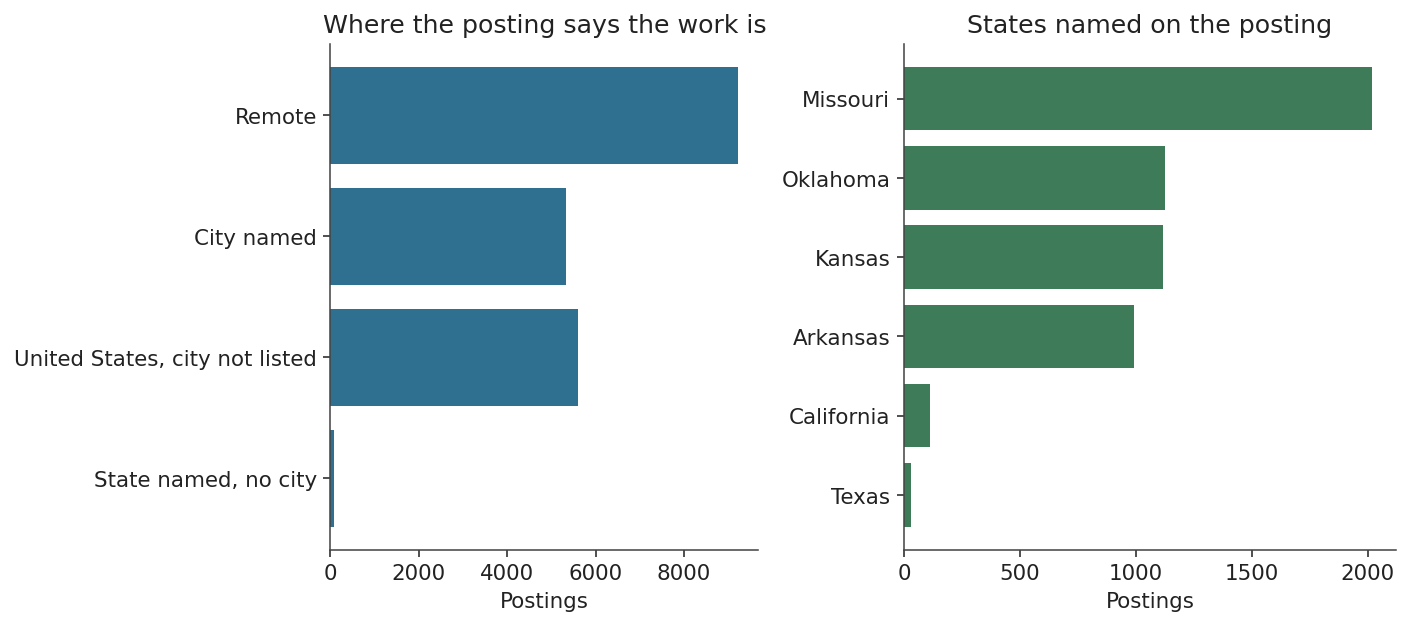

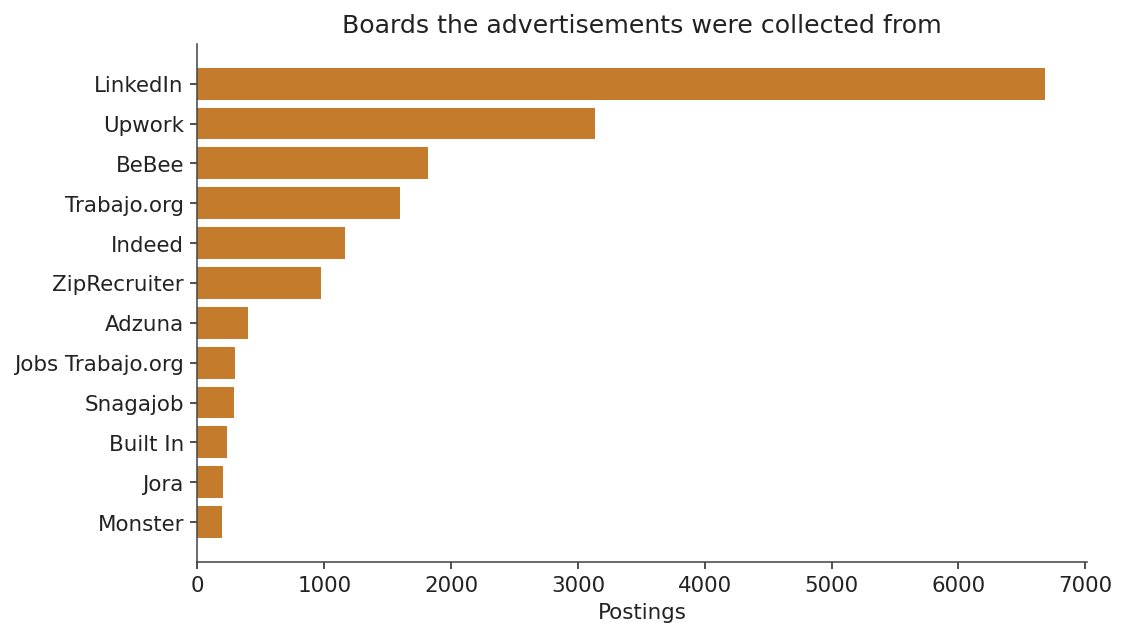

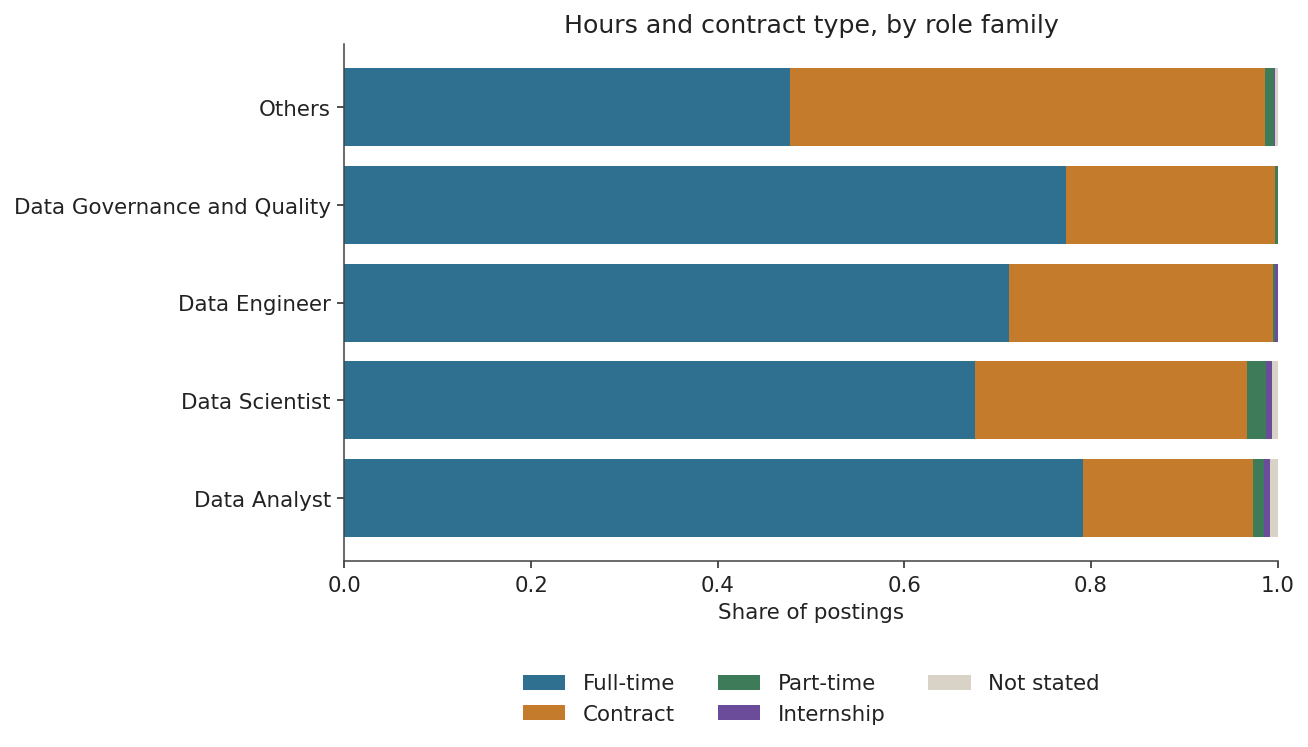

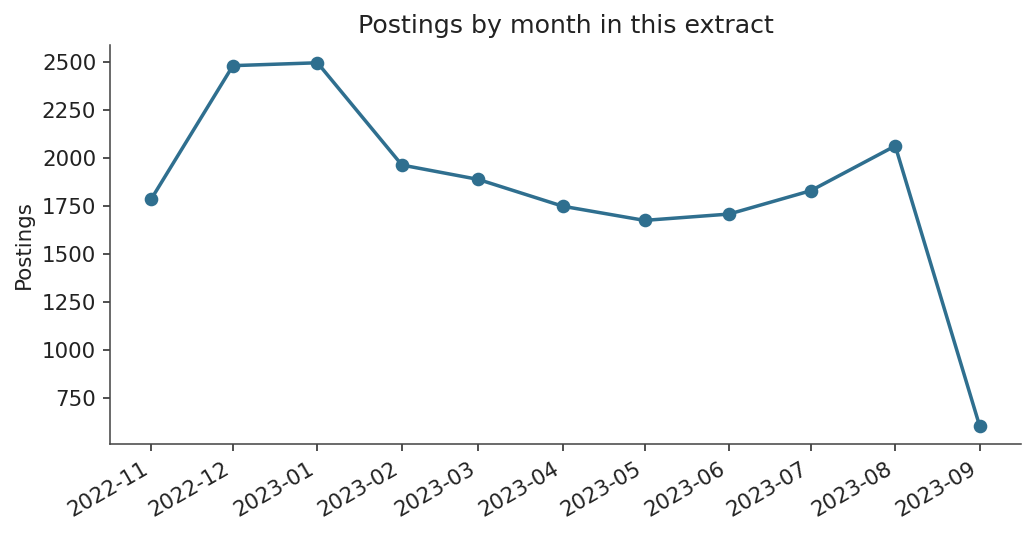

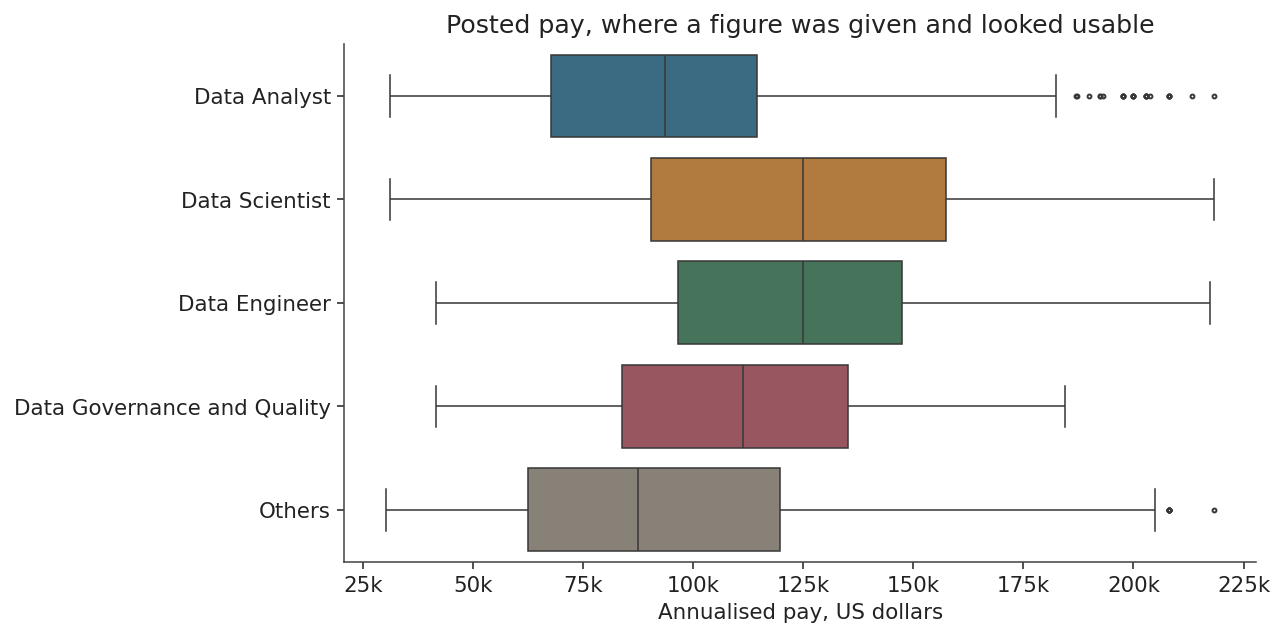

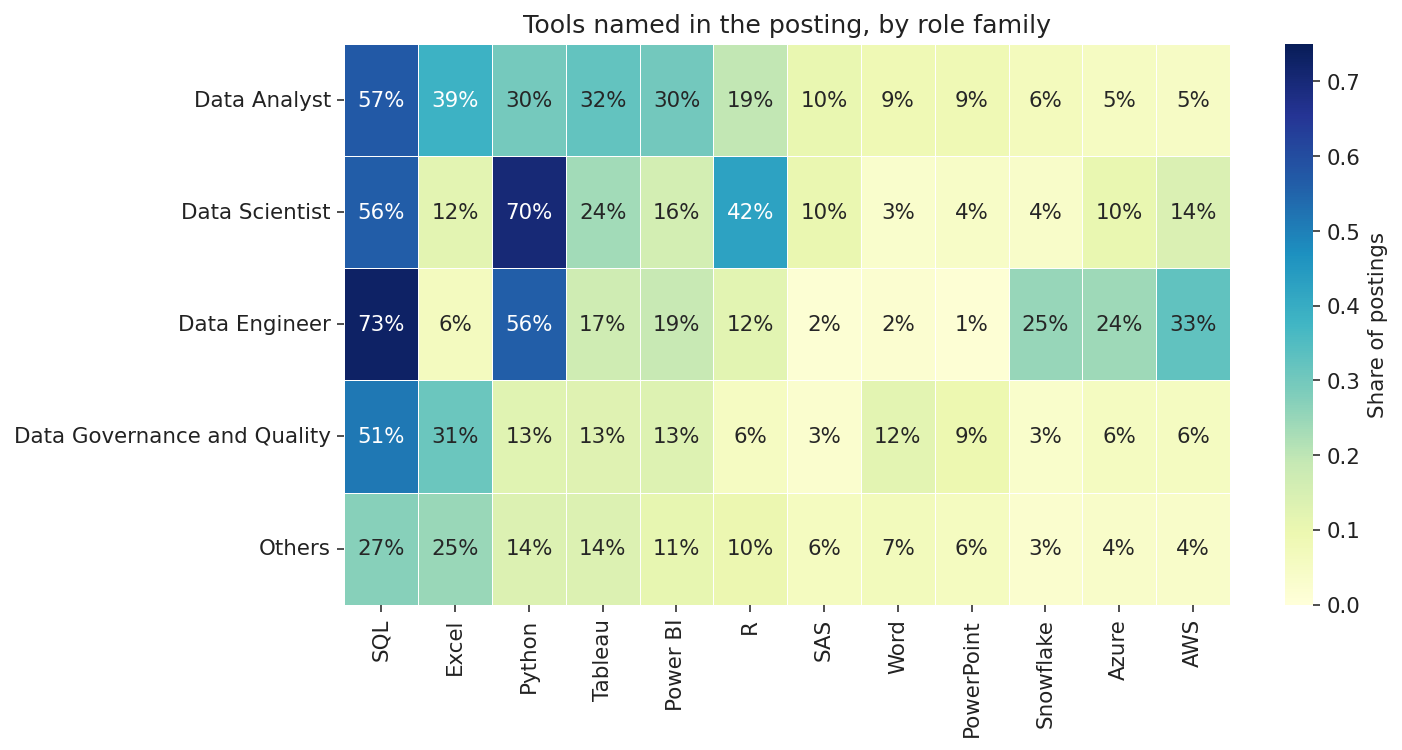

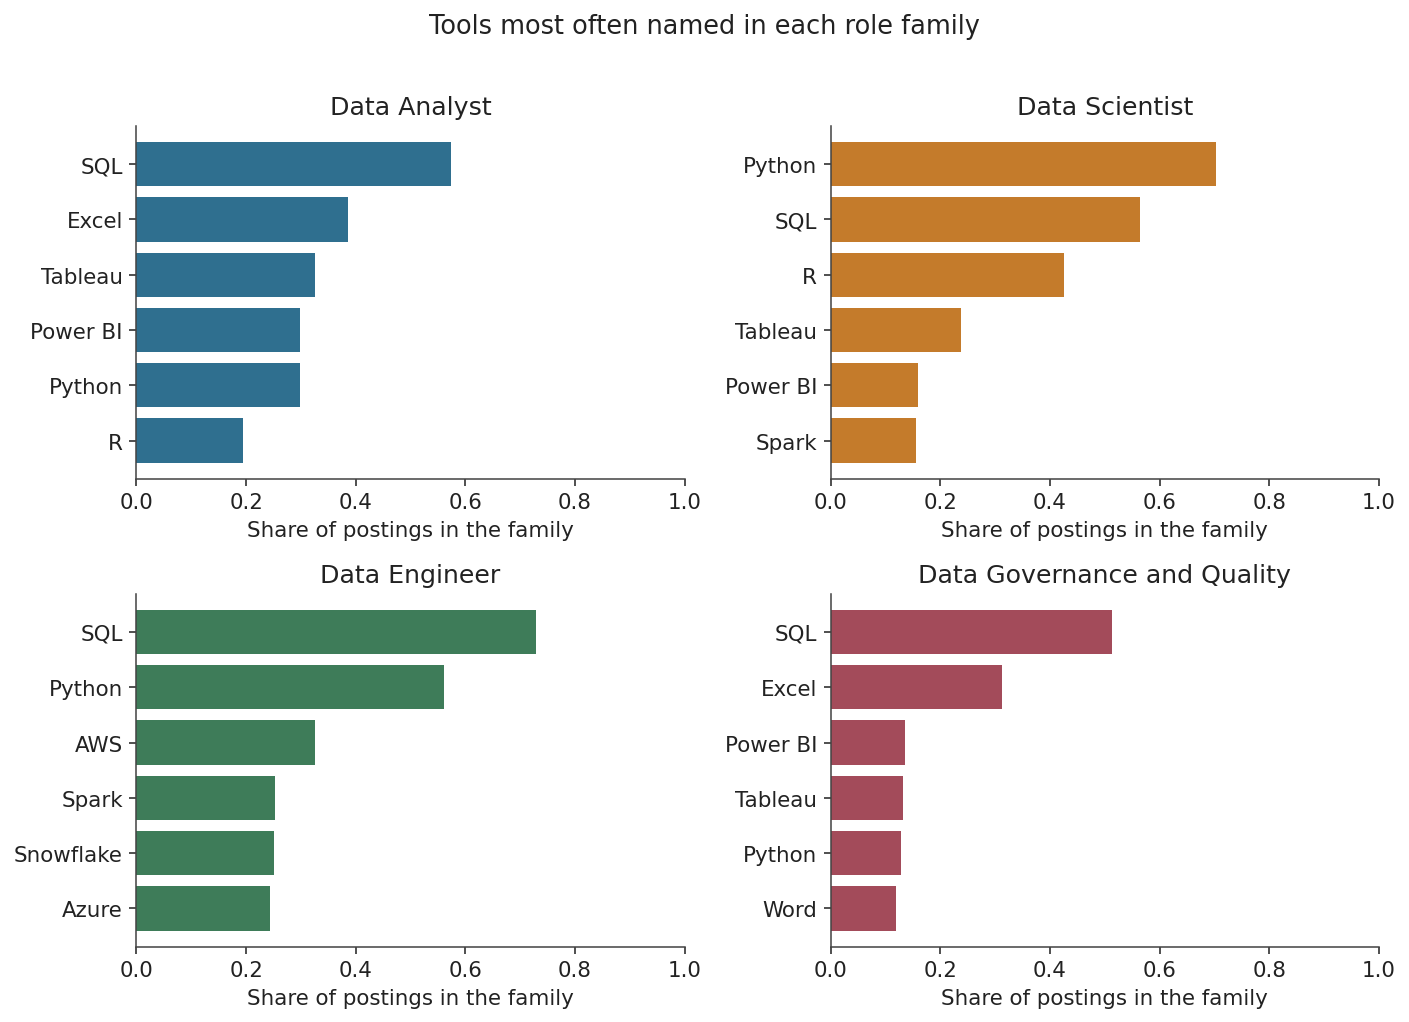

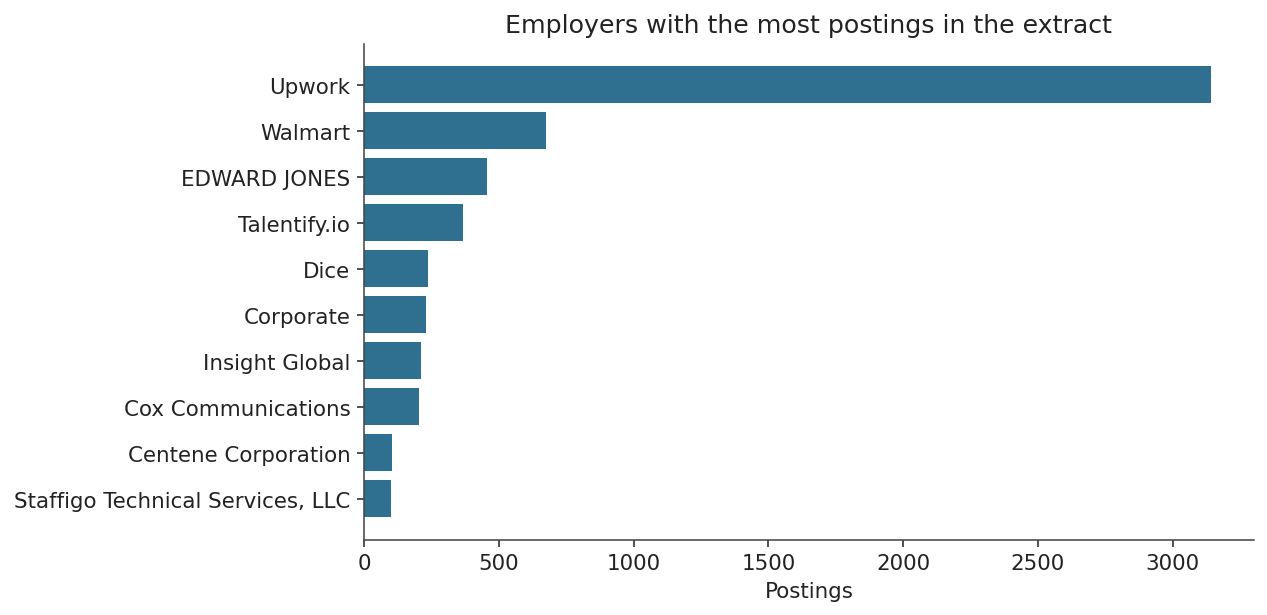

In [4]:
summary = make_figures(df, OUT_DIR / "figures")
from IPython.display import Image, display
for name in [
    "01_role_families.png",
    "03_location.png",
    "04_job_boards.png",
    "05_schedule.png",
    "06_volume_by_month.png",
    "07_salary.png",
    "08_skills_heatmap.png",
    "09_distinctive_skills.png",
    "10_companies.png",
]:
    display(Image(filename=str(OUT_DIR / "figures" / name)))


## 4. Requirements, which is the part worth keeping

SQL is the common tool. It is named in 57 percent of analyst postings, 56 percent of scientist postings, and 73 percent of engineer postings. The families separate on what sits next to SQL.

Analyst postings add Excel (39 percent), Tableau (32 percent), and Power BI (30 percent). Python is there too, but only in 30 percent of them. Scientist postings reverse that order: Python in 70 percent, R in 42 percent, and Excel in 12 percent. Engineer postings name Python in 56 percent and then a platform stack that the analyst postings barely mention: AWS (33 percent), Snowflake (25 percent), and Spark (25 percent on the family chart). Governance postings look like analyst postings with a smaller tool list, plus the language of policies, catalogs, and metadata that shows up later in the model terms.

Posted pay is thin. A usable figure exists for 3,574 postings, 18 percent of the cleaned file. Among those, the median is about $94,000 for analysts, $111,000 for governance, and $125,000 for scientists and engineers. The scientist and engineer boxes rest on 176 and 64 postings. They are a hint, not a salary survey.

Contract work is 18 percent of analyst postings and 51 percent of Others. Many of the Others titles are Upwork tasks ("Excel Expert", a one-off conversion from R to Python) rather than a standing job.


## 5. Classifiers

The text the models see is the description after the title and the role-family phrases have been removed. "Data analyst", "data scientist", "data engineer", "data governance", and "data quality" are taken out. Ordinary duty words such as "analysis" and "reports" are left in. Stopping those as well would hide the work itself.

The split is stratified, 80 percent train and 20 percent test. Grid search uses three-fold cross-validation inside the training set and scores macro F1. The test set is scored once. Class weights are balanced, except for naive Bayes, which has no class-weight switch in this setup, and except for the majority baseline. The vectorizer is a TF-IDF pipeline refit on each fold: unigrams and bigrams, English stop words, at most 4,000 terms.

Training takes a few minutes. The numbers below are from a completed run with `random_state=42`.


Naive Bayes: macro F1 0.425  accuracy 0.777  cv 0.434  153.8s  {'alpha': 0.1}
Support Vector Machine: macro F1 0.604  accuracy 0.791  cv 0.604  177.8s  {'C': 0.25}
Logistic Regression: macro F1 0.573  accuracy 0.740  cv 0.574  186.4s  {'C': 3.0}
Decision Tree: macro F1 0.374  accuracy 0.583  cv 0.350  234.7s  {'max_depth': 32, 'min_samples_leaf': 10}
Random Forest: macro F1 0.555  accuracy 0.750  cv 0.557  226.9s  {'max_depth': 16, 'min_samples_leaf': 5}
Best by macro F1: Support Vector Machine
Train 16,196   Test 4,049

Majority class               accuracy 0.746   macro F1 0.171   macro precision 0.149   macro recall 0.200
Naive Bayes                  accuracy 0.777   macro F1 0.425   macro precision 0.655   macro recall 0.367
Support Vector Machine       accuracy 0.791   macro F1 0.604   macro precision 0.575   macro recall 0.645
Logistic Regression          accuracy 0.740   macro F1 0.573   macro precision 0.518   macro recall 0.666
Decision Tree                accuracy 0.583   mac

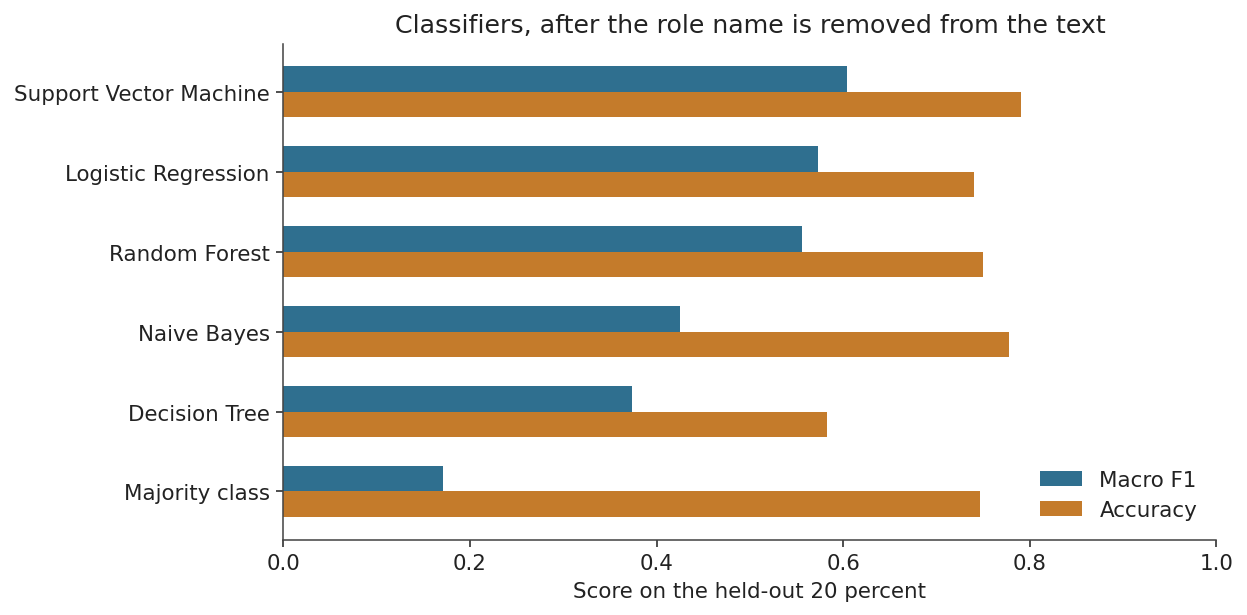

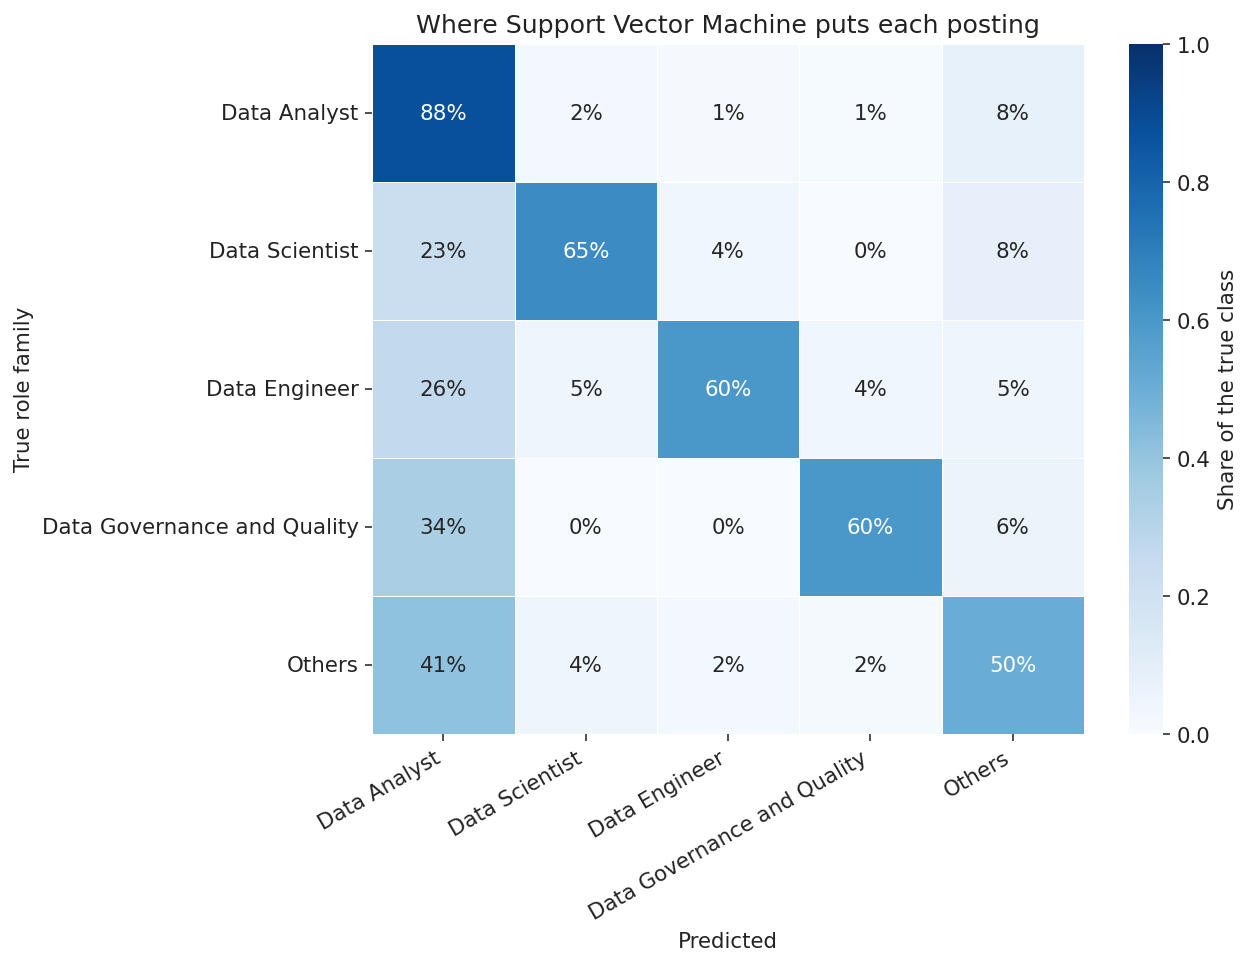

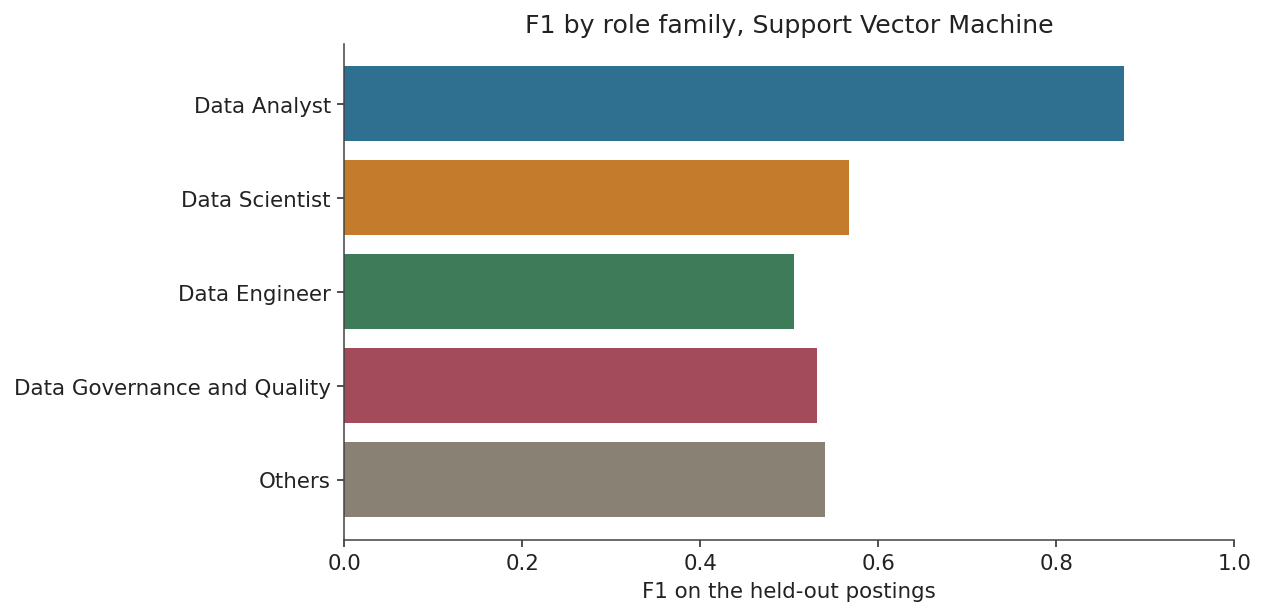

In [5]:
model_info = train_models(df)
plot_model_results(model_info, OUT_DIR / "figures")
from IPython.display import Image, display

print(f"Best by macro F1: {model_info['best_model']}")
print(f"Train {model_info['n_train']:,}   Test {model_info['n_test']:,}")
print()
for row in model_info["results"]:
    print(
        f"{row['model']:<28} accuracy {row['accuracy']:.3f}   "
        f"macro F1 {row['macro_f1']:.3f}   "
        f"macro precision {row['macro_precision']:.3f}   "
        f"macro recall {row['macro_recall']:.3f}"
    )
print()
for row in model_info["per_class"]:
    print(
        f"{row['category']:<32} precision {row['precision']:.3f}  "
        f"recall {row['recall']:.3f}  f1 {row['f1']:.3f}  n {row['support']}"
    )
print()
print("Terms the logistic model leans on")
for label, terms in model_info["logistic_terms"].items():
    kept = [item["term"] for item in terms if item["term"] not in {"ing", "sr", "include", "need"}]
    print(f"{label}: {', '.join(kept)}")
for name in ["11_model_comparison.png", "12_confusion_matrix.png", "13_f1_by_family.png"]:
    display(Image(filename=str(OUT_DIR / "figures" / name)))


## 6. How to read the scores

Accuracy of 0.791 for the linear support vector machine sounds strong until it is set next to the majority guess, which scores 0.746 by always answering "data analyst". The useful gap is the macro F1: 0.604 against 0.171. Naive Bayes has almost the same accuracy as the support vector machine and a much worse macro F1, because it rarely commits to a small class. Logistic regression and the random forest land close to each other, behind the linear SVM. The decision tree is last. Its accuracy, 0.589, is worse than guessing the majority class.

The confusion matrix says where the errors go. Analyst postings are recognised about 88 percent of the time. Scientist, engineer, and governance postings are recognised about 60 percent of the time, and when they are missed they are usually called analysts. Others is split almost in half with the analyst class. That is what a mixed leftover category looks like.

The logistic terms are readable, which is why that model is kept even though it is not the winner. Analysts pull in "tableau", "reports", and "excel". Engineers pull in "etl", "pipelines", "snowflake", "aws", "dbt", and "bigquery". Governance pulls in "policies", "catalog", "metadata", "privacy", and "standards". Scientists pull in "python", "algorithms", "predictive", and "models". The model is, in large part, rediscovering the tool list.

A fitted pipeline is applied to a new posting by masking the role name the same way and calling `predict`. Saving it with `joblib` is enough for a small Streamlit page that takes a description and returns a family. The page in the draft counted words and then overwrote the saved model. That is not a deployment.


In [6]:
def score_posting(pipeline, title, description):
    """Return a role family for one advertisement.

    `pipeline` is the fitted TF-IDF plus classifier, for example the
    support vector machine selected above.
    """
    return pipeline.predict([mask_role_language(title, description)])[0]


row = df.loc[df["job_category"] == "Data Scientist"].iloc[0]
print(row["title"])
print()
print(row["text_model"][:500])


Lead Data Science Analyst

discover a brighter future with us you ll do meaningful work from day 1 our collaborative culture is built on three core behaviors we play to win we get better every day we succeed together and we mean it we want you to grow and make a difference at one of the world s leading digital banking and payments companies we value what makes you unique so that you have an opportunity to shine come build your future while being the reason millions of people find a brighter financial future with discover 


## 7. What I would stand behind

The skill profiles are the result I would show a hiring manager. They use the whole cleaned file, they do not depend on a train-test split, and they match the way the families are usually described: analysts report, scientists model, engineers move data. The classifier is a rough second reader for a description that already looks like one of those families. It is not a system for standardising titles across companies, and the sample — one query, four states plus remote, rule-made labels — would not support that claim.
